In [24]:
from google.colab import files
uploaded = files.upload()

Saving sentiment_reviews.csv to sentiment_reviews (1).csv


In [25]:
import pandas as pd
import numpy as np
import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

import matplotlib.pyplot as plt
import seaborn as sns

In [26]:
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt')
nltk.download('omw-1.4')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [27]:
df = pd.read_csv("sentiment_reviews.csv")

df.head()

,review_id,review_text,sentiment
0,1,"The product quality is exceptional, exceeded a...",positive
1,2,Terrible customer service and the item arrived...,negative
2,3,"Average performance, decent for the price poin...",neutral
3,4,"Absolutely love this! Easy to setup, robust, a...",positive
4,5,Stopped working after two days. Extremely disa...,negative


In [28]:
# Remove neutral class (Task requires positive & negative classification)
df = df[df['sentiment'] != 'neutral'].reset_index(drop=True)

print(df['sentiment'].value_counts())

sentiment
positive    5
negative    4
Name: count, dtype: int64


In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   review_id    9 non-null      int64 
 1   review_text  9 non-null      object
 2   sentiment    9 non-null      object
dtypes: int64(1), object(2)
memory usage: 348.0+ bytes


In [30]:
df.columns

Index(['review_id', 'review_text', 'sentiment'], dtype='object')

In [31]:
X = df['review_text']
y = df['sentiment']

In [32]:
stop_words = set(stopwords.words('english'))

lemmatizer = WordNetLemmatizer()


def clean_text(text):

    # lowercase
    text = text.lower()

    # remove HTML tags
    text = re.sub('<.*?>', '', text)

    # remove punctuation and numbers
    text = re.sub('[^a-zA-Z]', ' ', text)

    # tokenize
    words = text.split()

    # stopword removal + lemmatization
    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    return " ".join(words)

In [33]:
df['clean_review'] = df['review_text'].apply(clean_text)

df.head()

,review_id,review_text,sentiment,clean_review
0,1,"The product quality is exceptional, exceeded a...",positive,product quality exceptional exceeded expectation
1,2,Terrible customer service and the item arrived...,negative,terrible customer service item arrived complet...
2,4,"Absolutely love this! Easy to setup, robust, a...",positive,absolutely love easy setup robust work flawlessly
3,5,Stopped working after two days. Extremely disa...,negative,stopped working two day extremely disappointed...
4,6,Customer support helped resolve my setup quest...,positive,customer support helped resolve setup question...


In [34]:
X = df['clean_review']
y = df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [35]:
tfidf = TfidfVectorizer(
    max_features=5000
)


X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)


print(X_train_tfidf.shape)

(7, 45)


In [36]:
nb_model = MultinomialNB()


nb_model.fit(
    X_train_tfidf,
    y_train
)


nb_prediction = nb_model.predict(
    X_test_tfidf
)

In [37]:
lr_model = LogisticRegression(
    max_iter=1000
)


lr_model.fit(
    X_train_tfidf,
    y_train
)


lr_prediction = lr_model.predict(
    X_test_tfidf
)

In [38]:
def evaluate_model(name, y_true, y_pred):

    print("=" * 40)
    print(name)
    print("=" * 40)

    print("Accuracy :", accuracy_score(y_true, y_pred))
    print("Precision:", precision_score(y_true, y_pred, average='weighted', zero_division=0))
    print("Recall   :", recall_score(y_true, y_pred, average='weighted', zero_division=0))
    print("F1 Score :", f1_score(y_true, y_pred, average='weighted', zero_division=0))

    print("\nClassification Report")
    print(classification_report(y_true, y_pred, zero_division=0))

In [39]:
evaluate_model(
    "Multinomial Naive Bayes",
    y_test,
    nb_prediction
)

Multinomial Naive Bayes
Accuracy : 0.5
Precision: 0.25
Recall   : 0.5
F1 Score : 0.3333333333333333

Classification Report
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         1
    positive       0.50      1.00      0.67         1

    accuracy                           0.50         2
   macro avg       0.25      0.50      0.33         2
weighted avg       0.25      0.50      0.33         2



In [40]:
evaluate_model(
    "Logistic Regression",
    y_test,
    lr_prediction
)

Logistic Regression
Accuracy : 0.5
Precision: 0.25
Recall   : 0.5
F1 Score : 0.3333333333333333

Classification Report
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         1
    positive       0.50      1.00      0.67         1

    accuracy                           0.50         2
   macro avg       0.25      0.50      0.33         2
weighted avg       0.25      0.50      0.33         2



In [46]:
def plot_confusion_matrix(y_true, y_pred, title):

    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(5,4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Negative","Positive"],
        yticklabels=["Negative","Positive"]
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(title)

    plt.show()

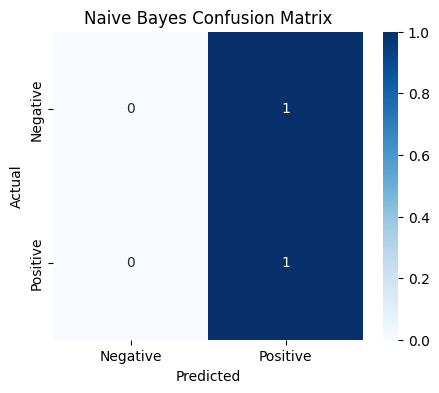

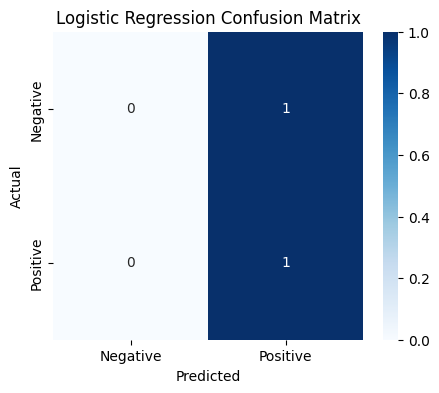

In [47]:
plot_confusion_matrix(
    y_test,
    nb_prediction,
    "Naive Bayes Confusion Matrix"
)

plot_confusion_matrix(
    y_test,
    lr_prediction,
    "Logistic Regression Confusion Matrix"
)

In [ ]:
results = pd.DataFrame({
    "Model":["Naive Bayes","Logistic Regression"],
    "Accuracy":[
        accuracy_score(y_test,nb_prediction),
        accuracy_score(y_test,lr_prediction)
    ],
    "Precision":[
        precision_score(y_test,nb_prediction,average="weighted",zero_division=0),
        precision_score(y_test,lr_prediction,average="weighted",zero_division=0)
    ],
    "Recall":[
        recall_score(y_test,nb_prediction,average="weighted",zero_division=0),
        recall_score(y_test,lr_prediction,average="weighted",zero_division=0)
    ],
    "F1":[
        f1_score(y_test,nb_prediction,average="weighted",zero_division=0),
        f1_score(y_test,lr_prediction,average="weighted",zero_division=0)
    ]
})

print(results)

In [42]:
def predict_sentiment(text):

    cleaned = clean_text(text)

    vector = tfidf.transform([cleaned])

    prediction = lr_model.predict(vector)[0]

    probability = lr_model.predict_proba(vector).max()

    print("Prediction :", prediction)
    print("Confidence :", round(probability*100,2),"%")

    return prediction

In [43]:
review1 = "This movie was amazing and I really loved it"

print(
    predict_sentiment(review1)
)

positive


In [48]:
import pickle

pickle.dump(
    lr_model,
    open("sentiment_model.pkl","wb")
)


pickle.dump(
    tfidf,
    open("tfidf_vectorizer.pkl","wb")
)

In [50]:
while True:

    review = input("Enter your review (type 'quit' to exit): ")

    if review.lower() == "quit":
        break

    predict_sentiment(review)

Enter your review (type 'quit' to exit): quit
